In [82]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)
print("NumPy Version :", np.__version__)

OpenCV Version: 5.0.0
NumPy Version : 2.5.1


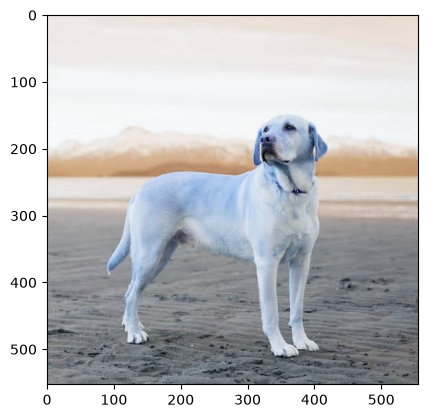

In [83]:
image = cv2.imread('image.jpg')
plt.imshow(image)
plt.show()

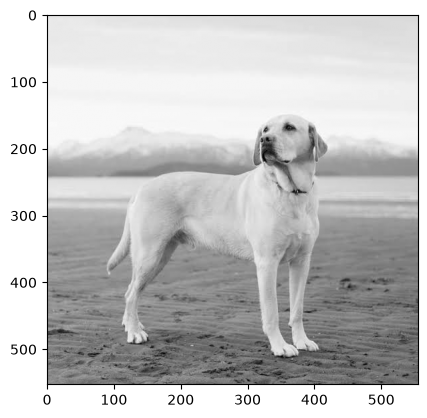

In [84]:
image = cv2.imread('image.jpg' , cv2.IMREAD_GRAYSCALE)
plt.imshow(image, cmap='gray')
plt.show()

In [85]:
def add_salt_and_pepper_noise(image, probability):
    noisy = image.copy()

    random = np.random.rand(*image.shape)

    noisy[random < (probability / 2)] = 0  # Pepper noise
    noisy[random > 1 - (probability / 2)] = 255  # Salt noise

    return noisy

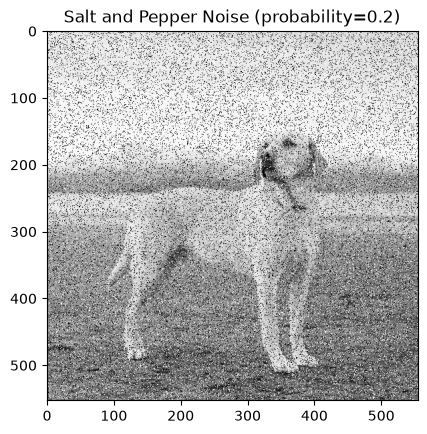

In [86]:
prob = 0.2
noisy_image = add_salt_and_pepper_noise(image, prob)
plt.imshow(noisy_image, cmap='gray')
plt.title(f'Salt and Pepper Noise (probability={prob})')
plt.show()

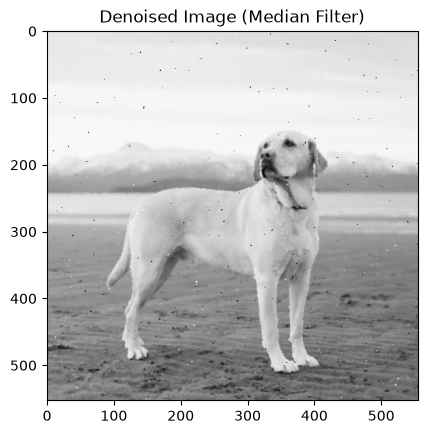

In [ ]:
# Removing Salt and Pepper Noise using Median Filter

def remove_salt_and_pepper_noise(image, kernel_size):
    denoised = cv2.medianBlur(image, kernel_size)
    return denoised

#plotting image after removing noise
denoised = remove_salt_and_pepper_noise(noisy, 3)
plt.imshow(denoised, cmap='gray')
plt.title('Denoised Image (Median Filter)')
plt.show()

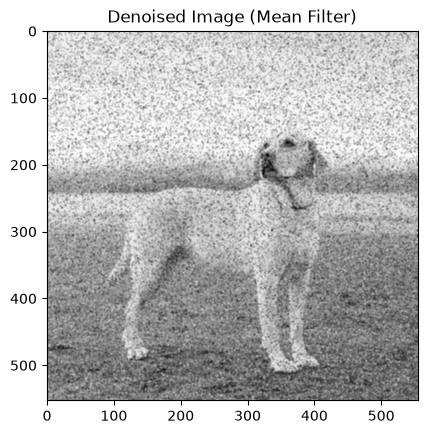

In [88]:
# Removing Salt and Pepper Noise using Mean Filter

def remove_salt_and_pepper_noise(image, kernel_size):
    denoised = cv2.blur(image, (kernel_size, kernel_size))
    return denoised

#plotting image after removing noise
denoised = remove_salt_and_pepper_noise(noisy, 3)
plt.imshow(denoised, cmap='gray')
plt.title('Denoised Image (Mean Filter)')
plt.show()

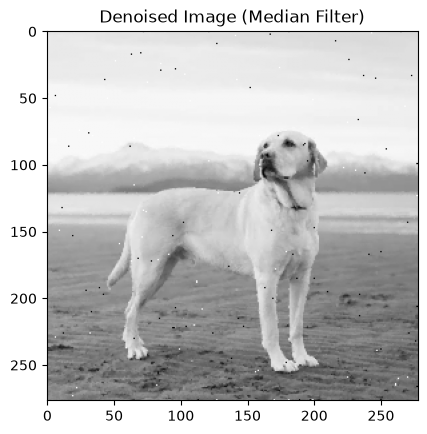

In [89]:
# Removing Salt and Pepper Noise using Median Filter + Stride

def remove_salt_and_pepper_noise(image, kernel_size,stride=1):
    denoised = cv2.medianBlur(image, kernel_size)

    if stride > 1:
        denoised = denoised[::stride, ::stride]

    return denoised

#plotting image after removing noise
stride_value = 2
denoised = remove_salt_and_pepper_noise(noisy, 3 ,stride=stride_value)
plt.imshow(denoised, cmap='gray')
plt.title('Denoised Image (Median Filter)')
plt.show()

In [90]:
#Median filter with reflection padding and stride

def median_filter(image, kernel_size, stride=1):

    h,w = image.shape
    pad = kernel_size // 2 #absolute division by 2 , answer returns integer (floor division)
    padded_image = np.pad(image, pad, mode='reflect')

    # Output dimensions
    out_h = ((h - kernel_size) // stride) + 1
    out_w = ((w - kernel_size) // stride) + 1

    output = np.zeros((out_h, out_w), dtype=image.dtype)

    # Mean filtering with stride
    for i in range(out_h):
        for j in range(out_w):
            window = padded_image[i*stride : i*stride + kernel_size, j*stride : j*stride + kernel_size]
            output[i, j] = np.median(window)
            
    return output


In [91]:
#Mean filter with reflection padding and stride

def mean_filter(image, kernel_size, stride=1):

    h,w = image.shape
    pad = kernel_size // 2 #absolute division by 2 , answer returns integer (floor division)
    padded_image = np.pad(image, pad, mode='reflect')

    # Output dimensions
    out_h = ((h - kernel_size) // stride) + 1
    out_w = ((w - kernel_size) // stride) + 1

    output = np.zeros((out_h, out_w), dtype=image.dtype)

    # Mean filtering with stride
    for i in range(out_h):
        for j in range(out_w):
            window = padded_image[i*stride : i*stride + kernel_size, j*stride : j*stride + kernel_size]
            output[i, j] = np.mean(window)
            
    return output


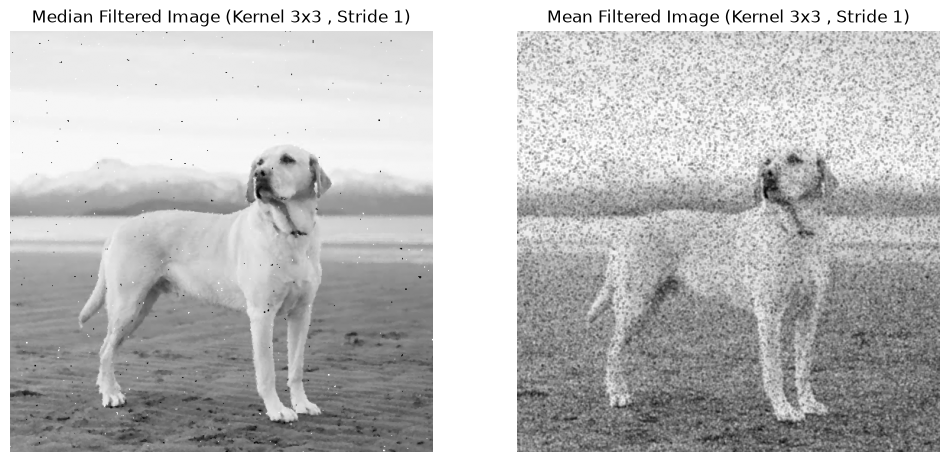

In [92]:
medianfilter_image = median_filter(noisy_image, kernel_size=3, stride=1)
meanfilter_image = mean_filter(noisy_image, kernel_size=3, stride=1)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(medianfilter_image, cmap='gray')
plt.title("Median Filtered Image (Kernel 3x3 , Stride 1)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(meanfilter_image, cmap='gray')
plt.title("Mean Filtered Image (Kernel 3x3 , Stride 1)")
plt.axis('off')
plt.show()

1) Varying Kernel Size

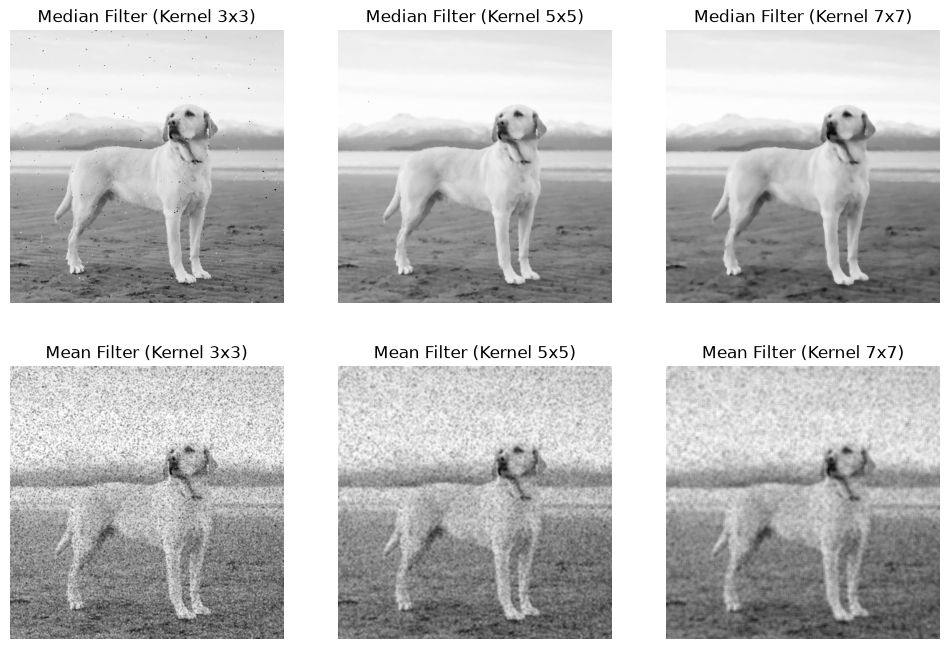

In [93]:
k3 = median_filter(noisy_image, kernel_size=3, stride=1)
k5 = median_filter(noisy_image, kernel_size=5, stride=1)
k7 = median_filter(noisy_image, kernel_size=7, stride=1)

k33 = mean_filter(noisy_image, kernel_size=3, stride=1)
k55 = mean_filter(noisy_image, kernel_size=5, stride=1)
k77 = mean_filter(noisy_image, kernel_size=7, stride=1)

plt.figure(figsize=(12, 8))
plt.subplot(2, 3, 1)
plt.imshow(k3, cmap='gray')
plt.title("Median Filter (Kernel 3x3)")
plt.axis('off')
plt.subplot(2, 3, 2)
plt.imshow(k5, cmap='gray')
plt.title("Median Filter (Kernel 5x5)")
plt.axis('off')
plt.subplot(2, 3, 3)
plt.imshow(k7, cmap='gray')
plt.title("Median Filter (Kernel 7x7)")
plt.axis('off')     

plt.subplot(2, 3, 4)
plt.imshow(k33, cmap='gray')
plt.title("Mean Filter (Kernel 3x3)")
plt.axis('off')
plt.subplot(2, 3, 5)
plt.imshow(k55, cmap='gray')
plt.title("Mean Filter (Kernel 5x5)")
plt.axis('off')
plt.subplot(2, 3, 6)
plt.imshow(k77, cmap='gray')
plt.title("Mean Filter (Kernel 7x7)")
plt.axis('off')

plt.show()

2) Varying Stride Size

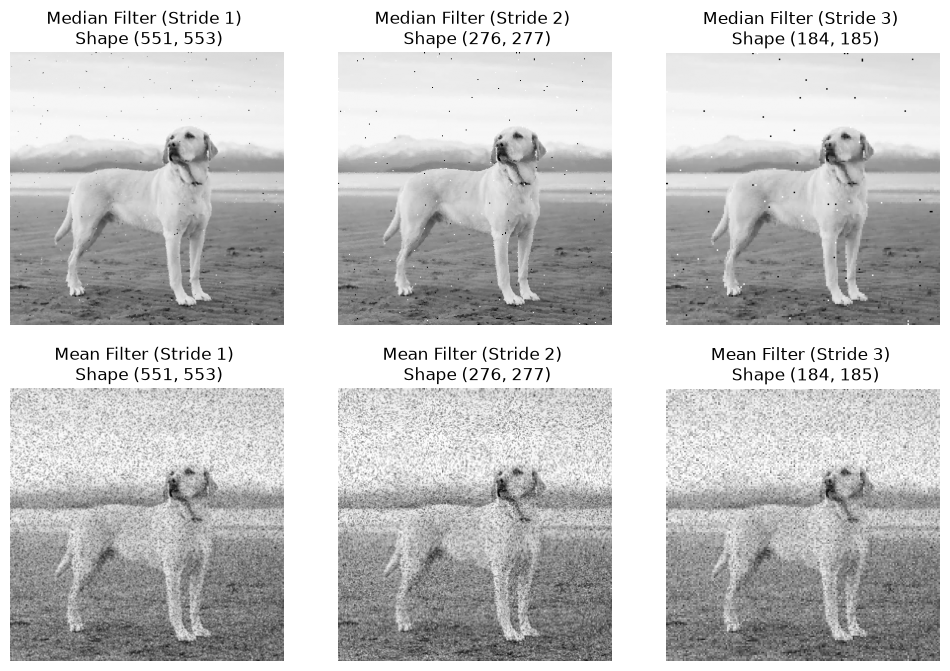

In [97]:
s1 = median_filter(noisy_image, kernel_size=3, stride=1)
s2 = median_filter(noisy_image, kernel_size=3, stride=2)
s3 = median_filter(noisy_image, kernel_size=3, stride=3)

s11 = mean_filter(noisy_image, kernel_size=3, stride=1)
s22 = mean_filter(noisy_image, kernel_size=3, stride=2)
s33 = mean_filter(noisy_image, kernel_size=3, stride=3)

plt.figure(figsize=(12, 8))
plt.subplot(2, 3, 1)
plt.imshow(s1, cmap='gray')
plt.title(f"Median Filter (Stride 1) \n Shape {s1.shape}")
plt.axis('off')
plt.subplot(2, 3, 2)
plt.imshow(s2, cmap='gray')
plt.title(f"Median Filter (Stride 2) \n Shape {s2.shape}")
plt.axis('off')
plt.subplot(2, 3, 3)
plt.imshow(s3, cmap='gray')
plt.title(f"Median Filter (Stride 3) \n Shape {s3.shape}")
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(s11, cmap='gray')
plt.title(f"Mean Filter (Stride 1) \n Shape {s11.shape}")
plt.axis('off')
plt.subplot(2, 3, 5)
plt.imshow(s22, cmap='gray')
plt.title(f"Mean Filter (Stride 2) \n Shape {s22.shape}")
plt.axis('off')
plt.subplot(2, 3, 6)
plt.imshow(s33, cmap='gray')
plt.title(f"Mean Filter (Stride 3) \n Shape {s33.shape}")
plt.axis('off')
plt.show()